# Part 4: Exploratory Data Analysis (EDA)
**Project:** Crop Recommendation System Using Machine Learning

Goal: understand the data before modelling. We look at class balance, feature distributions, correlations, how each crop differs in its growing conditions, and which features separate the crops best.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif

sns.set_theme(style="whitegrid")
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
OUT = "eda_figures"
os.makedirs(OUT, exist_ok=True)

def _save(fig, name):
    fig.savefig(f"{OUT}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

# Load the dataset (Part 3 found it clean: no missing values, no duplicates)
CSV = next((p for p in ["Crop_recommendation.csv", "../data/raw/Crop_recommendation.csv"] if os.path.exists(p)), None)
if CSV is None:
    try:
        from google.colab import files
        files.upload(); CSV = "Crop_recommendation.csv"
    except ImportError:
        raise FileNotFoundError("Place Crop_recommendation.csv next to this notebook.")
df = pd.read_csv(CSV)
df[TARGET] = df[TARGET].str.strip().str.lower()
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 1. Class balance
A balanced target means accuracy is a fair metric and no crop needs re-weighting.

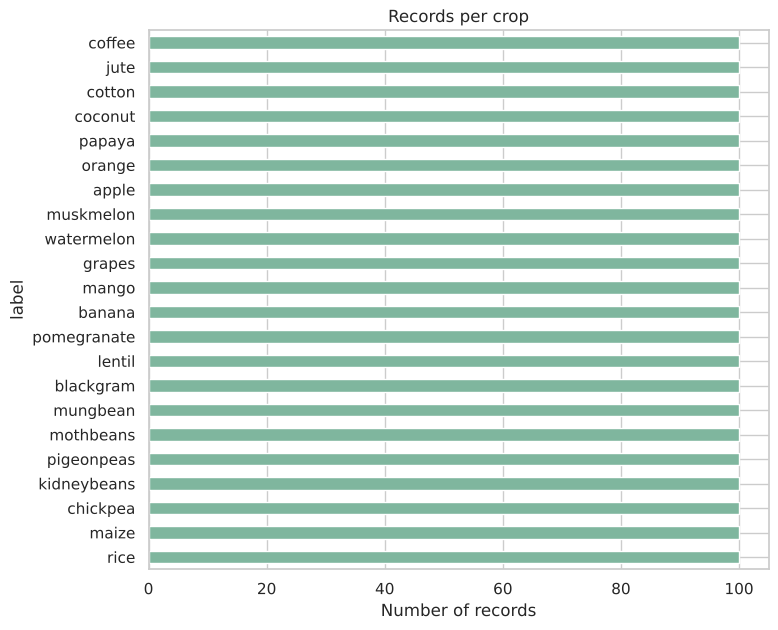

In [2]:
def class_distribution(df):
    counts = df[TARGET].value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(8, 7))
    counts.plot.barh(ax=ax, color="#7fb69e")
    ax.set_xlabel("Number of records")
    ax.set_title("Records per crop")
    _save(fig, "fig01_class_distribution.png")

class_distribution(df)

**Insight:** every one of the 22 crops has exactly 100 records (4.5% each), so the classes are perfectly balanced. Accuracy will be a reliable metric, and no resampling is needed.

## 2. Summary statistics and feature distributions

In [3]:
stats = df[FEATURES].describe().T
stats["skew"] = df[FEATURES].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00,0.51
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00,1.01
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00,2.38
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68,0.18
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98,-1.09
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94,0.28
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56,0.97


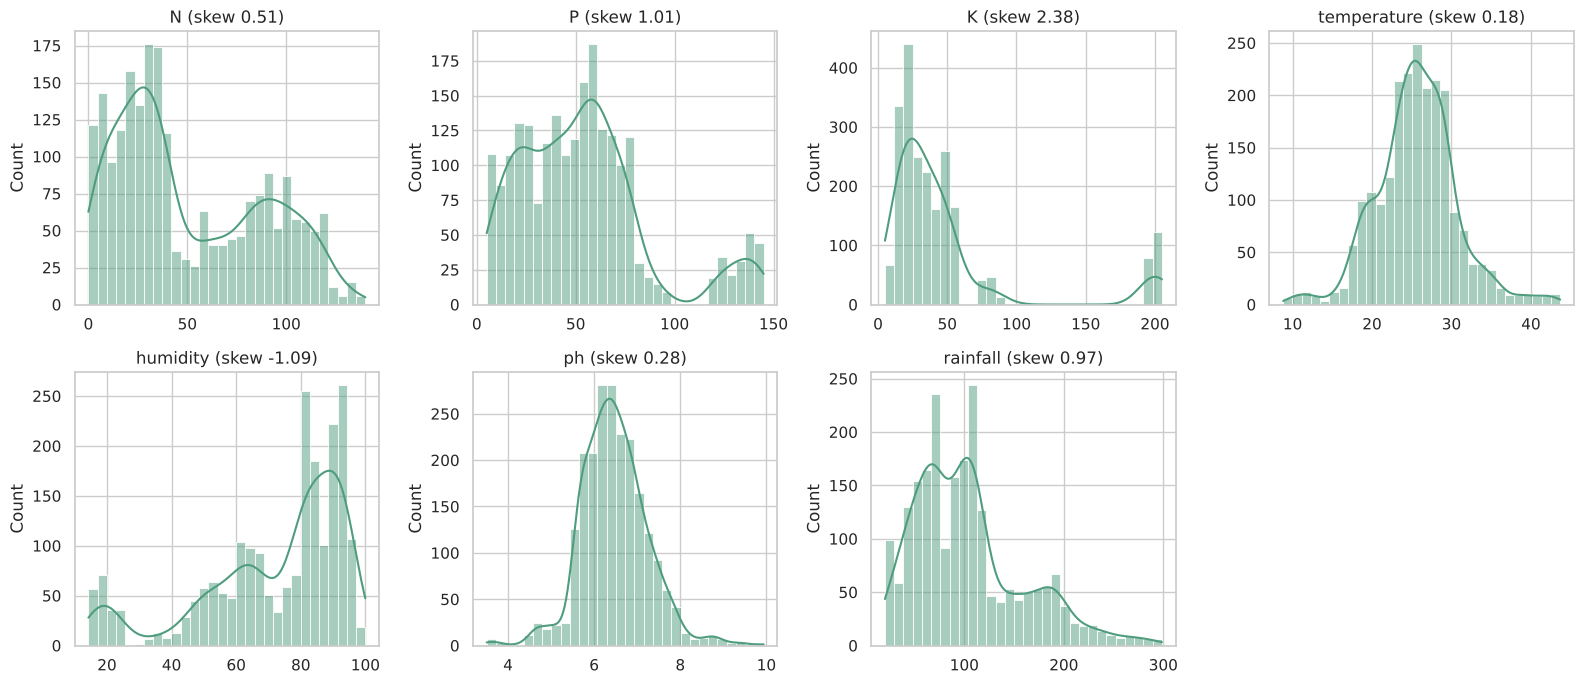

In [4]:
def feature_histograms(df):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, c in zip(axes.ravel(), FEATURES):
        sns.histplot(df[c], bins=30, kde=True, ax=ax, color="#4f9d7e")
        ax.set_title(f"{c} (skew {df[c].skew():.2f})")
        ax.set_xlabel("")
    axes.ravel()[-1].axis("off")
    plt.tight_layout()
    _save(fig, "fig02_feature_histograms.png")

feature_histograms(df)

**Insights**
- **K is the most skewed feature** (skew 2.38): most values lie between 5 and 85, but a separate group sits near 200. Those are the grapes and apple records.
- **P (1.01) and rainfall (0.97) are moderately right-skewed**, and **humidity is left-skewed** (-1.09), with many records at 80 to 100%.
- **Temperature (0.18) and pH (0.28) are close to symmetric**, centred around 25.6 °C and pH 6.5.
- The features have very different scales (rainfall averages 103, pH averages 6.5), which confirms that scaling is needed for distance-based models.

## 3. Correlation between features

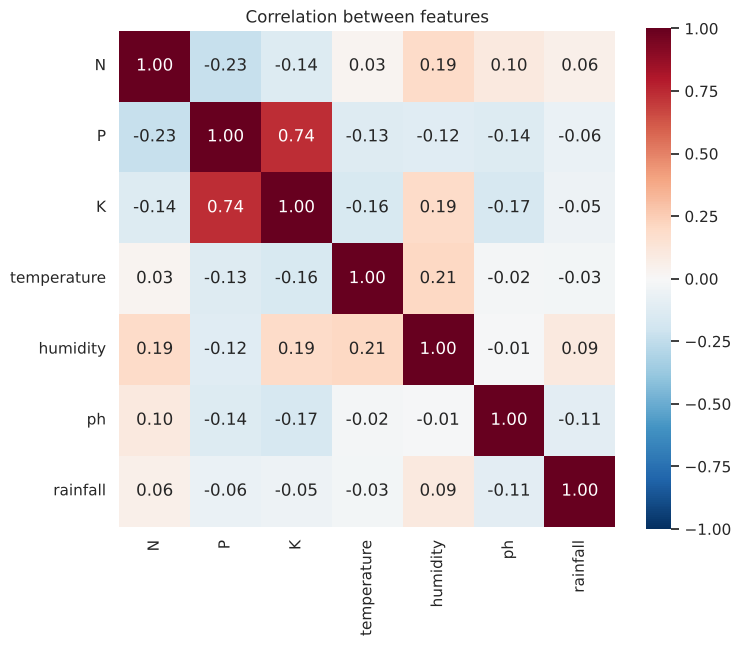

In [5]:
def correlation_heatmap(df):
    corr = df[FEATURES].corr()
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title("Correlation between features")
    _save(fig, "fig03_correlation_heatmap.png")

correlation_heatmap(df)

**Insights**
- **P and K are strongly positively correlated (r = 0.74)**. This is driven by apple and grapes, the only two crops that have both very high P (about 133) and very high K (about 200).
- **All other pairs are weak (|r| below 0.25)**, so the other features carry mostly independent information and there is little multicollinearity.
- Because P and K overlap partly, we will test in Part 5 whether keeping both helps the model.

## 4. How do the crops differ?

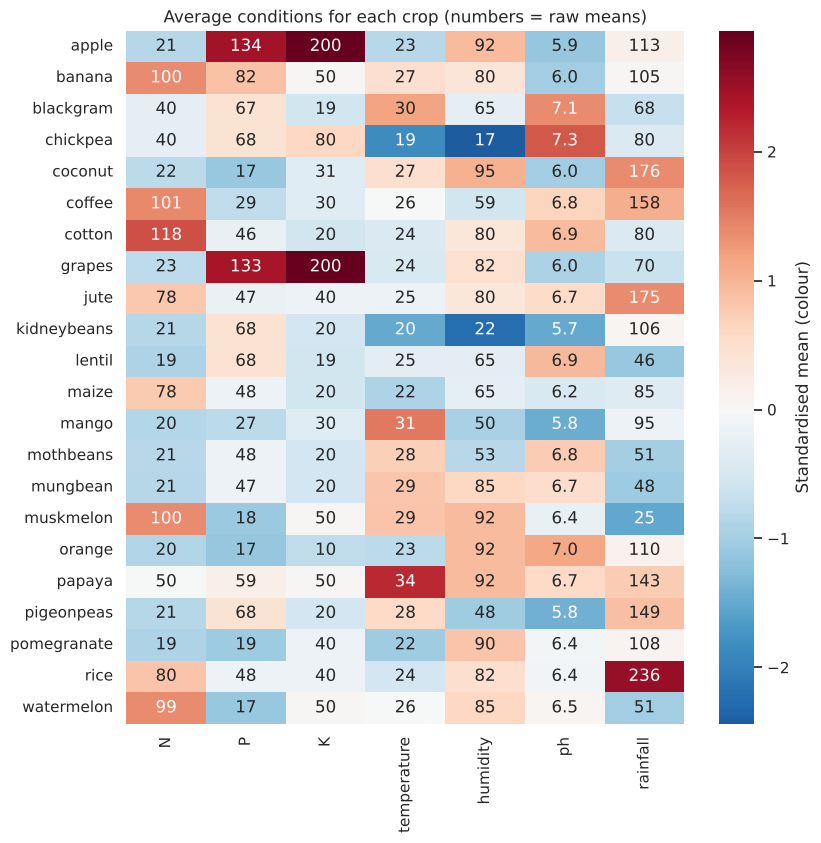

In [6]:
def crop_profile_heatmap(df):
    means = df.groupby(TARGET)[FEATURES].mean()
    z = (means - means.mean()) / means.std()            # compare features on one scale
    labels = means.round(0).astype(int).astype(str)
    labels["ph"] = means["ph"].round(1).astype(str)       # pH needs a decimal place
    fig, ax = plt.subplots(figsize=(9, 9))
    sns.heatmap(z, annot=labels, fmt="", cmap="RdBu_r", center=0,
                cbar_kws={"label": "Standardised mean (colour)"}, ax=ax)
    ax.set_title("Average conditions for each crop (numbers = raw means)")
    ax.set_ylabel("")
    _save(fig, "fig04_crop_profile_heatmap.png")

crop_profile_heatmap(df)

**Insights: what makes each crop distinctive**
- **Apple and grapes** need by far the highest P and K (K about 200, compared with 10 to 80 for every other crop).
- **Rice** needs the most rainfall (about 236 mm), followed by coconut and jute (about 175 mm).
- **Chickpea and kidneybeans** grow in very low humidity (about 17% and 22%), while coconut, papaya, muskmelon and orange need about 92 to 95%.
- **Muskmelon** needs the least rainfall (about 25 mm) and **lentil and mungbean** are also dry-season crops (under 50 mm).
- **Cotton, coffee, banana, muskmelon and watermelon** need the most nitrogen (about 100 to 118).
- **Papaya and mango** prefer the highest temperatures (about 34 °C and 31 °C), while chickpea is the coolest (about 19 °C).

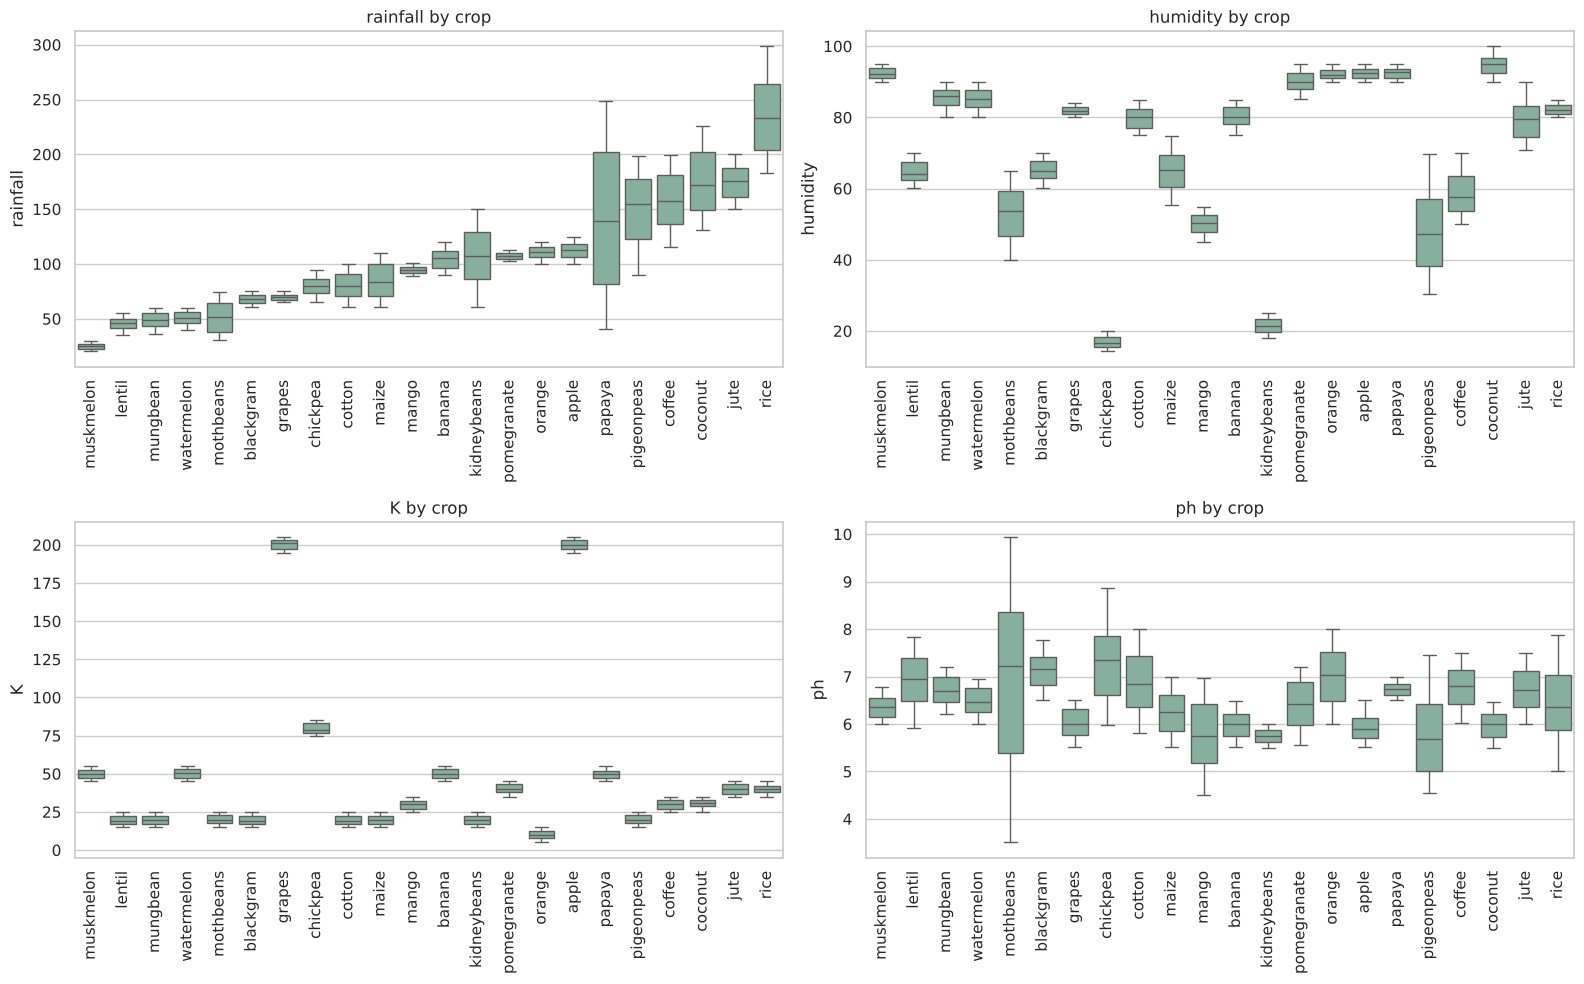

In [7]:
def boxplots_by_crop(df):
    order = df.groupby(TARGET)["rainfall"].median().sort_values().index
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for ax, c in zip(axes.ravel(), ["rainfall", "humidity", "K", "ph"]):
        sns.boxplot(data=df, x=TARGET, y=c, order=order, ax=ax, color="#7fb69e", fliersize=2)
        ax.set_title(f"{c} by crop")
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=90)
    plt.tight_layout()
    _save(fig, "fig05_boxplots_by_crop.png")

boxplots_by_crop(df)

**Insights**
- **K separates crops almost perfectly:** each crop has a narrow K band, and only grapes and apple (about 200) and chickpea (about 80) stand clear of the rest.
- **Humidity** splits crops into clear groups: very dry (chickpea, kidneybeans), mid-range (mothbeans, mango, pigeonpeas) and very humid (about 90 and above).
- **Rainfall** is tight for most crops, but papaya, pigeonpeas and coconut have wide ranges.
- **pH overlaps heavily between crops**, and mothbeans spans almost the whole pH range (3.5 to 9.9). pH is therefore expected to be the weakest single feature.

## 5. Relationships between features, coloured by crop

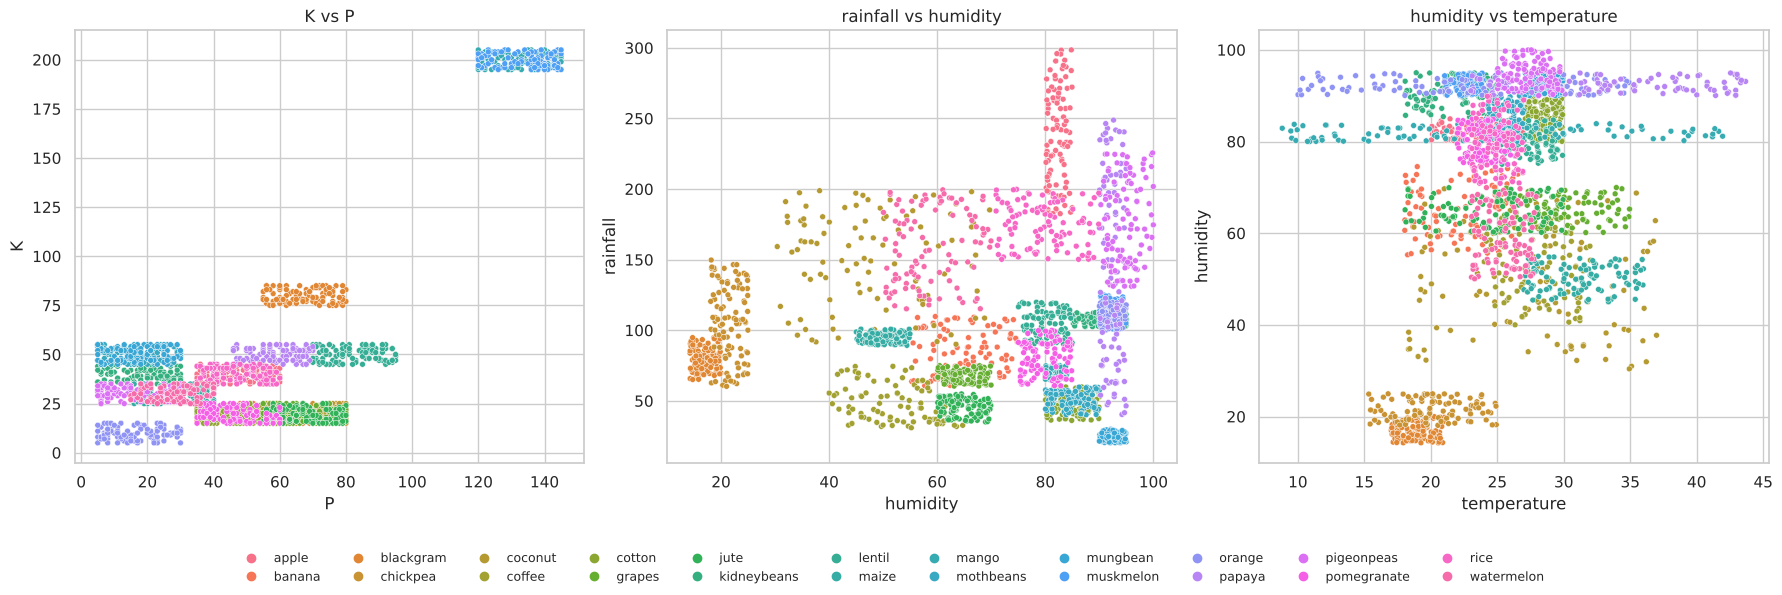

In [8]:
def scatter_relationships(df):
    pairs = [("P", "K"), ("humidity", "rainfall"), ("temperature", "humidity")]
    palette = sns.color_palette("husl", df[TARGET].nunique())
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (x, y) in zip(axes, pairs):
        sns.scatterplot(data=df, x=x, y=y, hue=TARGET, palette=palette, s=18, legend=False, ax=ax)
        ax.set_title(f"{y} vs {x}")
    handles = [plt.Line2D([], [], marker="o", ls="", color=col) for col in palette]
    fig.legend(handles, sorted(df[TARGET].unique()), loc="lower center", ncol=11, frameon=False, fontsize=9)
    plt.tight_layout(rect=(0, 0.1, 1, 1))
    _save(fig, "fig06_scatter_relationships.png")

scatter_relationships(df)

**Insights**
- Crops form **compact, well-separated clusters**, especially in the K vs P plot, where apple and grapes form an isolated group in the top right.
- The clusters have **sharp rectangular edges**, which suggests each crop's values were generated within fixed ranges rather than measured in real fields. This matches the earlier finding that no crop has any within-crop outliers.
- Because of this separation, we should expect **very high accuracy** in Part 7. This does not guarantee equally good performance on real farm data.
- The areas of overlap, mostly in the middle of the humidity vs rainfall and temperature vs humidity plots, are where the model is most likely to confuse crops.

## 6. Which features separate the crops best?
We use the ANOVA F-score: it measures how different the crop averages are for each feature, relative to the spread inside each crop. Higher means better separation.

In [9]:
def summary_tables(df):
    stats = df[FEATURES].describe().T
    stats["skew"] = df[FEATURES].skew()
    
    f, p = f_classif(df[FEATURES], df[TARGET])
    anova = pd.DataFrame({"feature": FEATURES, "F_statistic": f.round(0), "p_value": p}).sort_values(
        "F_statistic", ascending=False)
    
    return anova

summary_tables(df)

,feature,F_statistic,p_value
2,K,27238.0,0.000000e+00
4,humidity,3104.0,0.000000e+00
1,P,1886.0,0.000000e+00
0,N,898.0,0.000000e+00
6,rainfall,606.0,0.000000e+00
3,temperature,102.0,3.210979e-305
5,ph,60.0,6.493162e-199


**Insights**
- **K is by far the strongest feature** (F = 27,238), followed by **humidity (3,104), P (1,886), N (898) and rainfall (606)**.
- **Temperature (102) and pH (60) are the weakest.** They help less on their own but may still matter in combination.
- This is a first look at each feature separately. Part 8 will check it against the trained model's feature importance.

## 7. Closest crop pairs
Crops with similar average conditions are the ones a model is most likely to confuse. We measure the distance between crop averages (after standardising each feature).

In [10]:
from scipy.spatial.distance import pdist, squareform

means = df.groupby(TARGET)[FEATURES].mean()
z = (means - means.mean()) / means.std()
d = squareform(pdist(z))
np.fill_diagonal(d, np.inf)

pairs = sorted({tuple(sorted((means.index[i], means.index[j]))): d[i, j]
                for i in range(len(d)) for j in range(len(d))}.items(), key=lambda kv: kv[1])
pd.DataFrame([(a, b, round(v, 2)) for (a, b), v in pairs[:8]],
             columns=["crop_1", "crop_2", "distance"])

,crop_1,crop_2,distance
0,apple,grapes,1.03
1,muskmelon,watermelon,1.07
2,blackgram,mothbeans,1.28
3,lentil,mothbeans,1.32
4,coffee,jute,1.32
5,orange,pomegranate,1.39
6,jute,rice,1.39
7,mothbeans,mungbean,1.46


**Insight:** the most similar pairs are **grapes and apple**, **muskmelon and watermelon**, **mothbeans and blackgram**, **lentil and mothbeans**, and **coffee and jute**. We expect the few misclassifications in Part 7 to involve these crops.

## Summary of key findings
| Finding | Evidence |
|---|---|
| Classes are perfectly balanced | 100 records per crop |
| K is the most discriminating feature | ANOVA F = 27,238; K is about 200 only for apple and grapes |
| P and K are correlated; all other pairs are not | r(P, K) = 0.74; all other pairs below 0.25 in absolute value |
| pH and temperature are the weakest features | F = 60 and 102; heavy overlap in pH between crops |
| Crops form compact, well-separated clusters | Scatterplots; no within-crop outliers |
| Data looks generated within fixed ranges per crop | Sharp rectangular clusters |
| Most similar crops | grapes/apple, muskmelon/watermelon, mothbeans/blackgram |